In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# **excel**

In [ ]:
import pandas as pd

# Excel dosyasının yolunu belirtin
excel_dosyasi = '/content/drive/MyDrive/ali eren/veribilgisi.xlsx'

df = pd.read_excel(excel_dosyasi)


In [ ]:
df

,HASTANO,BIRADS KATEGORİSİ,MEME KOMPOZİSYONU,KADRAN BİLGİSİ (SAĞ),KADRAN BİLGİSİ (SOL),"Birads Skoru (EK BİLGİ OLARAK VERİLMİŞTİR, YARIŞMADA İSTENMEYECEKTİR)"
0,822670054,BI-RADS1-2,D,NaN,NaN,Kategori 1: Negatif (bir sorun yok)
1,822670190,BI-RADS1-2,C,NaN,NaN,Kategori 1: Negatif (bir sorun yok)
2,822670196,BI-RADS0,C,"[ ""ÜST DIŞ""]","[ ""MERKEZ""]",Kategori 0: Ek değerlendirme tetkiki yapılmalıdır
3,822670198,BI-RADS1-2,C,"[ ""MERKEZ""]","[ ""MERKEZ"", ""ÜST DIŞ""]",Kategori 2: İyi huylu bulgular
4,822670200,BI-RADS1-2,C,"[ ""MERKEZ""]","[ ""MERKEZ"", ""ÜST DIŞ""]",Kategori 2: İyi huylu bulgular
...,...,...,...,...,...,...
6756,845285700,BI-RADS4-5,D,NaN,"[ ""MERKEZ"", ""ÜST DIŞ""]",Kategori 4: Şüpheli bulgular - Biyopsi yapılma...
6757,845285709,BI-RADS4-5,D,NaN,"[ ""ÜST DIŞ""]",Kategori 4: Şüpheli bulgular - Biyopsi yapılma...
6758,845285900,BI-RADS4-5,B,"[ ""MERKEZ"", ""ALT İÇ""]",NaN,Kategori 5: Büyük olasılıkla kanser olabilir -...
6759,845285930,BI-RADS4-5,B,"[ ""ÜST DIŞ""]",NaN,Kategori 5: Büyük olasılıkla kanser olabilir -...


In [ ]:
deger_sayilari = df["BIRADS KATEGORİSİ"].value_counts()
deger_sayilari

BIRADS KATEGORİSİ
BI-RADS1-2    2683
BI-RADS4-5    2629
BI-RADS0      1449
Name: count, dtype: int64

In [ ]:
sütun_özellikleri = df.dtypes  # Sütun veri tipleri
sütun_isimleri = df.columns

In [ ]:
sütun_isimleri

Index(['HASTANO', 'BIRADS KATEGORİSİ', 'MEME KOMPOZİSYONU',
       'KADRAN BİLGİSİ (SAĞ)', 'KADRAN BİLGİSİ (SOL)',
       'Birads Skoru (EK BİLGİ OLARAK VERİLMİŞTİR, YARIŞMADA İSTENMEYECEKTİR)'],
      dtype='object')

In [ ]:

for sütun_adi in df.columns[1:]:
    print(f"Sütun: {sütun_adi}")
    benzersiz_degerler = df[sütun_adi].value_counts()
    print(benzersiz_degerler)
    print("----------------------")

In [ ]:
for sütun_adi in df.columns[1:]:
    print(f"Sütun: {sütun_adi}")
    benzersiz_degerler = df[sütun_adi].value_counts()
    print(benzersiz_degerler)
    print("----------------------")

# **import**

In [ ]:
import pandas as pd
import numpy as np
from glob import glob
import json
from tqdm import tqdm
import random
import cv2
import imageio
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
import shutil
import random
import yaml
from distutils.dir_util import copy_tree

In [ ]:
!unzip "/content/drive/MyDrive/zip data/CALC-TRAINING-png.zip"

# **dosyalama images/test**

In [ ]:
images = glob("/content/CALC-TRAINING-png/*/images/*.png")
print(len(images))
masks = glob("/content/CALC-TRAINING-png/*/masks/*.png")
print(len(masks))

1227
1227


In [ ]:
os.mkdir("/content/datasets")

os.mkdir("/content/datasets/images")
os.mkdir("/content/datasets/images/train")
os.mkdir("/content/datasets/images/test")
os.mkdir("/content/datasets/images/valid")

os.mkdir("/content/datasets/masks")
os.mkdir("/content/datasets/masks/train")
os.mkdir("/content/datasets/masks/test")
os.mkdir("/content/datasets/masks/valid")





In [ ]:
dataset_train_path = "/content/datasets/images/train"
dataset_valid_path ="/content/datasets/images/valid"
dataset_test_path = "/content/datasets/images/test"

In [ ]:
os.mkdir("alldata")
os.mkdir("alldata/images")
os.mkdir("alldata/masks")

In [ ]:
for i in images:
  shutil.move(i,"/content/alldata/images")

for i in masks:
  shutil.move(i,"/content/alldata/masks")

In [ ]:
trainimages = glob("/content/alldata/images/*.png")
trainlabels = glob("/content/alldata/masks/*.png")
print(len(trainimages))
print(len(trainlabels))


1227
1227


In [ ]:
train_image, test_image= train_test_split(trainimages,shuffle=True, test_size=0.25, random_state=42)
print("train count",len(train_image))
print("test count",len(test_image))


train count 920
test count 307


In [ ]:
train_image, valid_image= train_test_split(train_image,shuffle=True, test_size=0.2, random_state=42)
print("train count",len(train_image))
print("valid count",len(valid_image))

train count 736
valid count 184


In [ ]:
dataset_train_path = "/content/datasets/images/train"
dataset_valid_path ="/content/datasets/images/valid"
dataset_test_path = "/content/datasets/images/test"

In [ ]:
for train in train_image:
  shutil.move(train,dataset_train_path)

for valid in valid_image:
  shutil.move(valid,dataset_valid_path)

for test in test_image:
  shutil.move(test,dataset_test_path)


In [ ]:
datasetrain = glob(dataset_train_path +"/*.png")
datasetvalid = glob(dataset_valid_path + "/*.png")
datasettest = glob(dataset_test_path + "/*.png")
print(len(datasetrain))
print(len(datasetvalid))
print(len(datasettest))

736
184
307


In [ ]:
masktrain = glob("/content/alldata/masks/*png")

for maskname in masktrain:
  for trainame in datasetrain:
    maskname_ = maskname.split("_ROI.png")[0].split("/")[-1]
    trainame_ = trainame.split(".png")[0].split("/")[-1]
    if maskname_ == trainame_:
      #print(maskname)
      #print(trainame)
      #print(maskname_)
      #print(trainame_)
      #print("---")
      shutil.move(maskname,"/content/datasets/masks/train")

In [ ]:
maskvalid = glob("/content/alldata/masks/*png")

for maskname in maskvalid:

  for trainame in datasetvalid:
    maskname_ = maskname.split("_ROI.png")[0].split("/")[-1]
    trainame_ = trainame.split(".png")[0].split("/")[-1]
    if maskname_ == trainame_:
      print(maskname)
      print(trainame)
      print(maskname_)
      print(trainame_)
      print("---")
      shutil.move(maskname,"/content/datasets/masks/valid")

In [ ]:
masktest = glob("/content/alldata/masks/*png")

for maskname in masktest:

  for trainame in datasettest:
    maskname_ = maskname.split("_ROI.png")[0].split("/")[-1]
    trainame_ = trainame.split(".png")[0].split("/")[-1]
    if maskname_ == trainame_:
      print(maskname)
      print(trainame)
      print(maskname_)
      print(trainame_)
      print("---")
      shutil.move(maskname,"/content/datasets/masks/test")

In [ ]:
datasetrain = glob("/content/datasets/images/train" +"/*.png")
datasetvalid = glob("/content/datasets/images/valid" + "/*.png")
datasettest = glob("/content/datasets/images/test" + "/*.png")
print(len(datasetrain))
print(len(datasetvalid))
print(len(datasettest))

datasetrainlb = glob("/content/datasets/masks/train" +"/*.png")
datasetvalidlb = glob("/content/datasets/masks/valid" + "/*.png")
datasettestlb = glob("/content/datasets/masks/test" + "/*.png")
print(len(datasetrainlb))
print(len(datasetvalidlb))
print(len(datasettestlb))

736
184
307
736
184
307


In [ ]:
!zip -r seg_data_train_test_valid.zip /content/datasets

In [ ]:
shutil.copy("/content/seg_data_train_test_valid.zip","/content/drive/MyDrive/MammographyProject")

'/content/drive/MyDrive/MammographyProject/seg_data_train_test_valid.zip'

# **dosyalama test/images**

In [ ]:
images = glob("/content/CALC-TRAINING-png/*/images/*.png")
print(len(images))
masks = glob("/content/CALC-TRAINING-png/*/masks/*.png")
print(len(masks))

0
0


In [ ]:
os.mkdir("/content/datasets")

os.mkdir("/content/datasets/train")
os.mkdir("/content/datasets/train/images")
os.mkdir("/content/datasets/train/masks")

os.mkdir("/content/datasets/valid")
os.mkdir("/content/datasets/valid/images")
os.mkdir("/content/datasets/valid/masks")

os.mkdir("/content/datasets/test")
os.mkdir("/content/datasets/test/images")
os.mkdir("/content/datasets/test/masks")

In [ ]:
os.mkdir("alldata")
os.mkdir("alldata/images")
os.mkdir("alldata/masks")

In [ ]:
for i in images:
  shutil.move(i,"/content/alldata/images")

for i in masks:
  shutil.move(i,"/content/alldata/masks")

In [ ]:
trainimages = glob("/content/alldata/images/*.png")
trainlabels = glob("/content/alldata/masks/*.png")
print(len(trainimages))
print(len(trainlabels))


1227
1227


In [ ]:
train_image, test_image= train_test_split(trainimages,shuffle=True, test_size=0.25, random_state=42)
print("train count",len(train_image))
print("test count",len(test_image))


train count 920
test count 307


In [ ]:

train_image, valid_image= train_test_split(train_image,shuffle=True, test_size=0.2, random_state=42)
print("train count",len(train_image))
print("valid count",len(valid_image))

train count 736
valid count 184


In [ ]:
dataset_train_path = "/content/datasets/train/images"
dataset_valid_path ="/content/datasets/valid/images"
dataset_test_path = "/content/datasets/test/images"

In [ ]:
for train in train_image:
  shutil.move(train,dataset_train_path)

for valid in valid_image:
  shutil.move(valid,dataset_valid_path)

for test in test_image:
  shutil.move(test,dataset_test_path)


In [ ]:
datasetrain = glob(dataset_train_path +"/*.png")
datasetvalid = glob(dataset_valid_path + "/*.png")
datasettest = glob(dataset_test_path + "/*.png")
print(len(datasetrain))
print(len(datasetvalid))
print(len(datasettest))

736
184
307


In [ ]:
masktrain = glob("/content/alldata/masks/*png")

for maskname in masktrain:
  for trainame in datasetrain:
    maskname_ = maskname.split("_ROI.png")[0].split("/")[-1]
    trainame_ = trainame.split(".png")[0].split("/")[-1]
    if maskname_ == trainame_:
     # print(maskname)
     # print(trainame)
     # print(maskname_)
     # print(trainame_)
     # print("---")
      shutil.move(maskname,"/content/datasets/train/masks")

In [ ]:
maskvalid = glob("/content/alldata/masks/*png")

for maskname in maskvalid:

  for trainame in datasetvalid:
    maskname_ = maskname.split("_ROI.png")[0].split("/")[-1]
    trainame_ = trainame.split(".png")[0].split("/")[-1]
    if maskname_ == trainame_:
      print(maskname)
      print(trainame)
      print(maskname_)
      print(trainame_)
      print("---")
      shutil.move(maskname,"/content/datasets/valid/masks")

In [ ]:
masktest = glob("/content/alldata/masks/*png")

for maskname in masktest:

  for trainame in datasettest:
    maskname_ = maskname.split("_ROI.png")[0].split("/")[-1]
    trainame_ = trainame.split(".png")[0].split("/")[-1]
    if maskname_ == trainame_:
      print(maskname)
      print(trainame)
      print(maskname_)
      print(trainame_)
      print("---")
      shutil.move(maskname,"/content/datasets/test/masks")

In [ ]:
datasetrain = glob("/content/datasets/train/images" +"/*.png")
datasetvalid = glob("/content/datasets/valid/images" + "/*.png")
datasettest = glob("/content/datasets/test/images" + "/*.png")
print(len(datasetrain))
print(len(datasetvalid))
print(len(datasettest))

datasetrainlb = glob("/content/datasets/train/masks" +"/*.png")
datasetvalidlb = glob("/content/datasets/valid/masks" + "/*.png")
datasettestlb = glob("/content/datasets/test/masks" + "/*.png")
print(len(datasetrainlb))
print(len(datasetvalidlb))
print(len(datasettestlb))

736
184
307
736
184
307


In [ ]:
!zip -r seg_data_train_images.zip /content/datasets

In [ ]:
shutil.copy("/content/seg_data_train_images.zip","/content/drive/MyDrive/MammographyProject")

'/content/drive/MyDrive/MammographyProject/seg_data_train_images.zip'

In [ ]:
pip install wfdb


In [ ]:
import xml.etree.ElementTree as ET

# Function to process EKG data and create XML elements
def process_ekg_data(ekg_data):
  # Implement your logic here to process the raw EKG data (e.g., split into time-series values)
  # This function should return a list of XML elements representing the data
  # For example:
  data_elements = []
  for data_point in ekg_data:
    data_element = ET.SubElement(ET.Element("DataPoint"), "value")
    data_element.text = str(data_point)
    data_elements.append(data_element)
  return data_elements

# Read EKG data (replace with your actual data reading method)
ekg_data = open("/content/1.ekg", "rb").read()

# Process data and get XML elements
data_elements = process_ekg_data(ekg_data)

# Create XML root element
root = ET.Element("EKGData")

# Add data elements to the root
for data_element in data_elements:
  root.append(data_element)

# Create XML string
tree = ET.tostring(root, encoding="utf-8")

# Save the XML data to a file
with open("ekg_data1.xml", "wb") as xml_file:
  xml_file.write(tree)

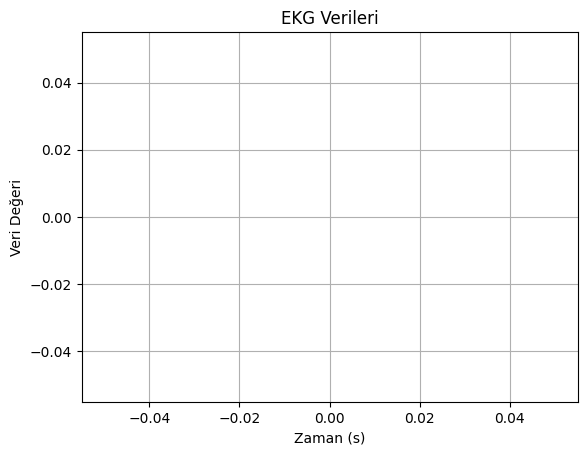

In [ ]:
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

# XML dosyasını okuyun
tree = ET.parse("ekg_data1.xml")
root = tree.getroot()

# Zaman ve veri değerlerini listelerde saklayın
timestamps = []
data_values = []

# XML öğelerini işleyin
for data_element in root.findall("DataPoint"):
  timestamp = float(data_element.find("timestamp").text)
  data_value = float(data_element.find("value").text)
  timestamps.append(timestamp)
  data_values.append(data_value)

# EKG dalga formunu çizin
plt.plot(timestamps, data_values)
plt.xlabel("Zaman (s)")
plt.ylabel("Veri Değeri")
plt.title("EKG Verileri")
plt.grid(True)
plt.show()

In [ ]:
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt

# Function to read XML file and extract EKG data
def read_ekg_data_from_xml(xml_file):
    try:
        tree = ET.parse(xml_file)
        root = tree.getroot()
        ekg_data = []

        for data_element in root.iter("DataPoint"):
            value_element = data_element.find("Value")
            if value_element is not None:
                try:
                    value = float(value_element.text)
                    ekg_data.append(value)
                except ValueError as e:
                    print(f"Could not convert value '{value_element.text}' to float: {e}")

        return ekg_data

    except ET.ParseError as e:
        print(f"Error parsing XML file '{xml_file}': {e}")
        return []

# XML dosyasını oku ve EKG verilerini al
xml_file_path = "ekg_data1.xml"
ekg_data = read_ekg_data_from_xml(xml_file_path)

if ekg_data:
    # Zaman serisi olarak görselleştirme
    plt.figure(figsize=(10, 6))
    plt.plot(ekg_data, marker='o', linestyle='-', color='b', label='EKG Data')
    plt.xlabel('Time')
    plt.ylabel('Signal Value')
    plt.title('EKG Signal Visualization')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("No valid EKG data found.")

No valid EKG data found.


In [ ]:
import xml.etree.ElementTree as ET

# Function to process EKG data and create XML elements
def process_ekg_data(ekg_data):
  # Implement your logic here to process the raw EKG data (e.g., split into time-series values)
  # This function should return a list of XML elements representing the data
  # For example:
  data_elements = []
  for data_point in ekg_data:
    data_element = ET.SubElement(ET.Element("DataPoint"), "value")
    data_element.text = str(data_point)
    data_elements.append(data_element)
  return data_elements

# Read EKG data (replace with your actual data reading method)
ekg_data = open("/content/1.ekg", "rb").read()

# Process data and get XML elements
data_elements = process_ekg_data(ekg_data)

# Create XML root element
root = ET.Element("EKGData")

# Add data elements to the root
for data_element in data_elements:
  root.append(data_element)

# Create XML string
tree = ET.tostring(root, encoding="utf-8")

# Save the XML data to a file
with open("ekg_data.xml", "wb") as xml_file:
  xml_file.write(tree)